# VGGT from scratch: one transformer that turns photos into 3D 🏛️
### *VGGT: Visual Geometry Grounded Transformer* (Wang, Chen, Karaev, Vedaldi, Rupprecht, Novotny - Oxford VGG & Meta AI, CVPR 2025) - explained for a beginner, rebuilt in pure PyTorch

**What it does, in one sentence:** you give VGGT a handful of ordinary photos of a scene; in **one forward pass** (under a second) it hands back, for every photo, **where the camera was**, **how far away each pixel is**, **the 3D position of each pixel**, and **features for tracking points** between photos.

Before VGGT, getting that required a long classical pipeline (find matching points, solve geometry, run an optimiser called *bundle adjustment* for seconds to minutes). VGGT's bet: *"3D reconstruction is just another prediction problem - throw a big plain transformer and lots of 3D-labelled data at it."*

<img src="vggt_assets/paper_fig1_overview.png" width="760"/>

**(paper) Figure 1** - input photos on the left; VGGT's output on the right: a 3D point cloud of the scene, camera frustums (the little pyramids), depth maps and point tracks.

| step | question | what we do |
|---|---|---|
| 1 | What is "3D reconstruction" and what were people doing before? | pinhole camera, epipolar geometry, the old pipeline |
| 2 | What exactly does VGGT output? | camera `g`, depth `D`, point map `P`, tracks `T` |
| 3 | What is the network? | the paper's architecture figure, token by token |
| 4 | A tiny 3D world to experiment in | we build a renderer with ground-truth cameras/depth, and verify the geometry |
| 5 | **Build it:** patchify images into tokens | pure PyTorch |
| 6 | **Build it:** camera + register tokens (and why frame 1 is special) | pure PyTorch |
| 7 | **Build it:** attention and the transformer block | pure PyTorch, checked against PyTorch's own |
| 8 | **Build it:** *Alternating Attention* - VGGT's key idea | pure PyTorch, with experiments |
| 9 | **Build it:** camera head and dense (depth/point/track) head | pure PyTorch |
| 10 | Put it together: `MiniVGGT` | parameter count by part |
| 11 | The loss: how it learns without being told the scale | uncertainty loss, normalisation |
| 12 | Train it on our toy world and measure | vs. naive baselines |
| 13 | Does Alternating Attention really beat plain global attention? | our mini ablation, next to the paper's |
| 14 | The real model + how to run it | size, training recipe, usage |
| 15 | Applications | what you can do with it |
| 16 | Cheat sheet and further reading | |

*Prerequisites:* know what a neural network and a transformer's "attention" roughly are (we re-explain attention from scratch in step 7). If residual connections are new to you, see the companion notebook `01_resnet_residual_learning.ipynb` - every transformer block below uses them. CPU only.

*Figure credits:* **(paper)** figures are from Wang et al. 2025 (arXiv:2503.11651). Web diagrams are from Wikimedia Commons: *Pinhole camera model* by O. Peters (CC BY-SA 4.0), *Epipolar geometry* by A. Nordmann (CC BY-SA 3.0), church photos by `.gs8` (CC BY-SA 3.0), *Vision Transformer* by D. V. Godoy (CC BY 4.0).

In [1]:
import math, time, copy
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"   # training device; everything else runs on CPU
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
FRAME_C, GLOBAL_C, CAM_C, DEPTH_C = "#1c7ed6", "#d9480f", "#2f9e44", "#9c36b5"

CHECKS = []
def check(name, ok, detail=""):
    """Record + print PASS/FAIL. Every claim in this notebook is backed by one of these."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

## Step 1 - What is 3D reconstruction, and why was it hard?

### A camera squashes 3D into 2D
A photo throws away one number per pixel: **how far away** the thing was. The standard mathematical model is the **pinhole camera**:

<table><tr><td><img src="vggt_assets/web_pinhole_camera.png" width="430"/></td><td>

*(web, CC BY-SA 4.0)* Light from a point in the world travels in a straight line through a single point - the **centre of projection** `O` - and lands on the **image plane**. Three things define the camera:

* **where it is and which way it faces** -> *extrinsics*: a rotation `R` and a translation `t` (6 numbers)
* **how zoomed-in it is** -> *intrinsics*: focal length / **field of view** (`principal distance c` in the picture)
* the **principal point** `H` - where the optical axis hits the image (VGGT assumes it is the image centre)

Every pixel therefore corresponds to a **ray** leaving the camera; the 3D point is *somewhere along that ray*. Depth tells you *where*.

</td></tr></table>

### Two photos pin the depth down
If the same physical point appears in two photos taken from different places, its two rays *cross* in 3D (**triangulation**). The geometric constraint relating the two views is **epipolar geometry**:

<table><tr><td><img src="vggt_assets/web_epipolar_geometry.png" width="380"/></td><td><img src="vggt_assets/web_epipolar_church_lines.png" width="460"/></td></tr></table>

*(web)* **Left:** a point `X` seen from two cameras `OL`, `OR`. A point in the left image can only appear on one **line** (the epipolar line) in the right image. **Right:** a real example - each coloured point on the left image has its match somewhere along the same-coloured line in the right image.

### The classical pipeline (Structure-from-Motion, SfM)
1. **Detect & match** keypoints between all pairs of photos.
2. **Estimate** the relative camera poses from the matches (epipolar geometry, RANSAC).
3. **Triangulate** 3D points.
4. **Bundle adjustment (BA):** an iterative optimiser that jointly nudges *all* cameras and *all* points to minimise reprojection error. Accurate, but slow (seconds-minutes), fragile when views barely overlap, and a pile of hand-built components (COLMAP is the classic tool).

VGGT asks: *can one network replace all four steps?*

## Step 2 - What VGGT predicts

The network is a function of `N` images `I_1 ... I_N` (each `3 x H x W`). For **every** image it returns four things:

| symbol | name | shape | meaning |
|---|---|---|---|
| `g_i` | **camera** | 9 numbers | quaternion `q` (4, the rotation) + translation `t` (3) + field of view (2). Principal point assumed at the image centre. |
| `D_i` | **depth map** | `H x W` | distance along the camera's forward axis for each pixel |
| `P_i` | **point map** | `3 x H x W` | the **(x, y, z) of each pixel's 3D point**, in the coordinates of **camera 1** |
| `T_i` | **track features** | `C x H x W` | per-pixel descriptors; a small tracking module uses them to follow a point across images |

Two ideas to hold on to:

* **Frame 1 is the reference.** Everything is expressed in camera 1's coordinate system, so camera 1's output is "do nothing": rotation = identity `q=[0,0,0,1]`, translation = `0`. (There has to be *some* reference - a photo alone does not say where the world's origin is.)
* **Outputs are redundant on purpose.** Depth + camera *determine* the point map (we verify this formula in code in Step 4). The authors still train the network to output **all of them**, because predicting extra related things made the *main* result better (paper ablation, Table 6; we repeat their numbers below).

**(paper) Figure 3 - VGGT vs. the previous method DUSt3R** (which only takes *two* photos at a time and needs a slow global optimisation afterwards): VGGT reads 1, 2 or 32 views in one pass; on 32 views DUSt3R needs > 200 s, VGGT < 0.6 s.

<img src="vggt_assets/paper_fig3_vs_dust3r.png" width="640"/>

## Step 3 - The network, in one picture

**(paper) Figure 2 - architecture overview**

<img src="vggt_assets/paper_fig2_architecture.png" width="820"/>

Read it left to right:

1. **Input images** (a few photos of one scene).
2. **DINO**: each image is cut into square **patches** and each patch becomes one **token** (a vector). Think of tokens as the "words" of an image. *(The real model starts from a pretrained DINO vision transformer; we use a plain patch embedding.)*
3. **Concat / add camera token:** next to each frame's patch tokens, the network adds one extra learnable **camera token** (orange) - a slot whose job is to *collect everything the model knows about that camera*. (Four "register" tokens are added as well - see Step 6.)
4. **Alternating attention x L:** the heart of the model. Layers alternate between **Frame attention** (yellow: tokens look only at tokens of *their own* image) and **Global attention** (blue: tokens look at tokens of *all* images). Repeated `L = 24` times in the real model.
5. **Heads:** the camera tokens go to the **camera head** -> camera poses. The patch tokens go to a **DPT head** -> depth maps, point maps and tracking features.

That is all. There are **no cross-attention layers and no hand-built geometry** (no epipolar constraints, no RANSAC, no bundle adjustment). The paper's phrase: *"minimal 3D inductive biases"* - the transformer is trusted to learn geometry from data.

The transformer family tree, if you know ViT: VGGT's tokens are exactly ViT tokens:

<img src="vggt_assets/web_vit.png" width="520"/>

*(web, CC BY 4.0)* A ViT cuts the image into patches, embeds each, adds positional encoding and runs a transformer. VGGT does this for **every** input image, then lets the images talk to each other through the global-attention layers.

## Step 4 - A tiny 3D world to build in

To build and *test* a VGGT we need training data with **ground-truth cameras and depth**. The real model uses ~17 datasets (CO3D, ScanNet, Kubric, ...). We make our own: a **checkered floor with three coloured spheres**, photographed by **3 cameras** at 32 x 32 pixels, with exact depth, exact camera poses, and exact 3D points (rendered with closed-form ray-sphere and ray-plane intersections - no libraries).

Three small geometry helpers first - read them, they are the "physics" under everything else:

* `look_at`: build a camera pose (`R`, `t`) from a position and a target.
* `quat_to_mat` / `mat_to_quat`: a rotation as 4 numbers (quaternion) <-> a 3x3 matrix. VGGT predicts quaternions.
* `unproject(depth, camera)`: **turn a depth map + a camera into 3D points.** For pixel `(u,v)` with depth `d`: the point in the camera's frame is `d * (x/z, y/z, 1)`, then `R^T (X_cam - t)` moves it into camera 1's frame.

In [2]:
def quat_to_mat(q):
    """Quaternion (x, y, z, w) -> 3x3 rotation matrix. (VGGT writes the identity rotation as [0,0,0,1].)"""
    x, y, z, w = F.normalize(q, dim=-1).unbind(-1)
    return torch.stack([1-2*(y*y+z*z), 2*(x*y-z*w),   2*(x*z+y*w),
                        2*(x*y+z*w),   1-2*(x*x+z*z), 2*(y*z-x*w),
                        2*(x*z-y*w),   2*(y*z+x*w),   1-2*(x*x+y*y)], -1).reshape(*q.shape[:-1], 3, 3)

def mat_to_quat(R):
    """3x3 rotation matrix -> quaternion (x, y, z, w) with w >= 0 (removes the q / -q ambiguity)."""
    m00, m11, m22 = R[..., 0, 0], R[..., 1, 1], R[..., 2, 2]
    a = torch.sqrt(torch.clamp(torch.stack([1+m00+m11+m22, 1+m00-m11-m22, 1-m00+m11-m22, 1-m00-m11+m22], -1), min=0))   # = 2|w|, 2|x|, 2|y|, 2|z|
    r = lambda i, j: R[..., i, j]
    cand = torch.stack([torch.stack([a[..., 0]**2, r(2,1)-r(1,2), r(0,2)-r(2,0), r(1,0)-r(0,1)], -1),
                        torch.stack([r(2,1)-r(1,2), a[..., 1]**2, r(1,0)+r(0,1), r(0,2)+r(2,0)], -1),
                        torch.stack([r(0,2)-r(2,0), r(1,0)+r(0,1), a[..., 2]**2, r(2,1)+r(1,2)], -1),
                        torch.stack([r(1,0)-r(0,1), r(2,0)+r(0,2), r(2,1)+r(1,2), a[..., 3]**2], -1)], -2)
    cand = cand / (2 * a[..., None].clamp(min=0.1))                      # numerically safest row = the largest component
    wxyz = cand[F.one_hot(a.argmax(-1), 4) > 0].reshape(*R.shape[:-2], 4)
    q = torch.cat([wxyz[..., 1:], wxyz[..., :1]], -1)                     # -> (x, y, z, w)
    return torch.where(q[..., 3:] < 0, -q, q)

def look_at(pos, target, up=(0., 0., 1.)):
    """World->camera rotation R and translation t for a camera at `pos` looking at `target`
    (OpenCV convention: x right, y down, z forward;  X_cam = R X_world + t)."""
    up = torch.tensor(up, dtype=pos.dtype, device=pos.device).expand_as(pos)
    fwd = F.normalize(target - pos, dim=-1)
    right = F.normalize(torch.cross(fwd, up, dim=-1), dim=-1)
    down = torch.cross(fwd, right, dim=-1)
    R = torch.stack([right, down, fwd], -2)                               # rows are the camera axes
    return R, -(R @ pos[..., None]).squeeze(-1)

def pixel_rays(fov, H, W):
    """Unnormalised ray direction (x/z, y/z, 1) for every pixel; principal point = image centre (as in VGGT)."""
    v, u = torch.meshgrid((torch.arange(H) + .5) / H * 2 - 1, (torch.arange(W) + .5) / W * 2 - 1, indexing="ij")
    th = torch.tan(fov / 2)[..., None, None]                              # (...,1,1)
    return torch.stack([u * th, v * th, torch.ones_like(u) * th.new_ones(th.shape)], -3)   # (...,3,H,W)

def unproject(depth, cam, H, W):
    """THE geometry formula behind 'depth + camera = point map'.
    depth (B,N,H,W), cam (B,N,9)=[quat(4), t(3), fov(2)]  ->  3D points in the FIRST camera's frame, (B,N,3,H,W)."""
    R = quat_to_mat(cam[..., :4]); t = cam[..., 4:7]
    X_cam = depth[..., None, :, :] * pixel_rays(cam[..., 7], H, W)        # point in camera i's frame (z = depth)
    return torch.einsum("bnji,bnjhw->bnihw", R, X_cam - t[..., None, None])             # R^T (X_cam - t)

In [3]:
# geometry sanity: round-trip a batch of random rotations through quaternions
torch.manual_seed(0)
q = F.normalize(torch.randn(1000, 4), dim=-1)
R = quat_to_mat(q); q2 = mat_to_quat(R)
check("rotation matrices from quaternions are orthonormal (R R^T = I)", (R @ R.transpose(-1, -2) - torch.eye(3)).abs().max() < 1e-5)
check("matrix -> quaternion recovers the rotation (R(q) == R(q'))", (quat_to_mat(q2) - R).abs().max() < 1e-5)
check("canonical quaternions have w >= 0", bool((q2[:, 3] >= 0).all()))

PASS  rotation matrices from quaternions are orthonormal (R R^T = I)
PASS  matrix -> quaternion recovers the rotation (R(q) == R(q'))
PASS  canonical quaternions have w >= 0


Now the world generator `make_batch`. Pay attention to the last lines: it expresses **everything in camera 1's frame** and then **divides by the average distance of the 3D points to the origin** - the paper's *ground-truth coordinate normalisation* (Step 11 explains why).

In [4]:
LIGHT = F.normalize(torch.tensor([0.4, 0.3, 0.86]), dim=0)

def make_batch(B, N=3, H=32, W=32, gen=None):
    """A tiny 'world': a checkered ground plane + 3 coloured spheres, photographed from N cameras.
    Returns images, depth, point map, camera vectors - all expressed in the FIRST camera's frame and
    scale-normalised exactly like the paper's 'ground truth coordinate normalisation'."""
    rnd = lambda *s: torch.rand(*s, generator=gen)
    # --- scene
    xy, radii = rnd(B, 3, 2) * 2 - 1, 0.3 + 0.3 * rnd(B, 3)                                               # sphere centre (x, y) and radius
    centers = torch.cat([xy, radii[..., None]], -1)                                                       # z = radius: sphere rests on the ground
    colors = 0.2 + 0.8 * rnd(B, 3, 3)
    # --- cameras on a ring around the scene; camera 0 is the reference frame
    az = rnd(B, 1) * 2 * math.pi + torch.cat([torch.zeros(B, 1), (rnd(B, N - 1) * 2 - 1) * 0.7], 1)
    rad, height = 3.5 + rnd(B, 1), 3.5 + rnd(B, 1)
    pos = torch.stack([rad * torch.cos(az), rad * torch.sin(az), height.expand(B, N)], -1)               # (B,N,3)
    target = torch.cat([(rnd(B, 1, 2) - .5) * .4, torch.full((B, 1, 1), .3)], -1).expand(B, N, 3)
    fov = ((45 + 15 * rnd(B, 1)) * math.pi / 180).expand(B, N)
    R, t = look_at(pos, target)                                                                           # world -> cam
    # --- ray cast (closed-form ray/plane and ray/sphere), s is the z-depth because rays are (x/z, y/z, 1)
    rays_c = pixel_rays(fov, H, W)                                                                        # (B,N,3,H,W)
    d = torch.einsum("bnji,bnjhw->bnihw", R, rays_c)                                                      # world-space direction
    o = pos[..., None, None]                                                                              # (B,N,3,1,1)
    s_ground = torch.where(d[:, :, 2] < 0, -o[:, :, 2] / d[:, :, 2].clamp(max=-1e-6), torch.full_like(d[:, :, 2], 1e9))
    best, hit = s_ground, torch.zeros_like(s_ground, dtype=torch.long)                                    # 0 = ground, k+1 = sphere k
    a = (d * d).sum(2)
    for k in range(3):
        oc = o - centers[:, None, k, :, None, None]
        b = 2 * (oc * d).sum(2); c = (oc * oc).sum(2) - radii[:, None, k, None, None] ** 2
        disc = b * b - 4 * a * c; sq = torch.sqrt(disc.clamp(min=0))
        s = (-b - sq) / (2 * a)
        ok = (disc > 0) & (s > 0) & (s < best); best = torch.where(ok, s, best); hit = torch.where(ok, torch.full_like(hit, k + 1), hit)
    depth = best                                                                                          # (B,N,H,W)
    p = o + depth[:, :, None] * d                                                                         # world hit point
    normal = torch.zeros_like(p); normal[:, :, 2] = 1
    albedo = (0.25 + 0.5 * ((p[:, :, 0].floor() + p[:, :, 1].floor()) % 2))[:, :, None] * torch.tensor([.8, .9, 1.], dtype=p.dtype)[:, None, None]
    for k in range(3):
        m = (hit == k + 1)[:, :, None]
        nk = F.normalize(p - centers[:, None, k, :, None, None], dim=2)
        normal = torch.where(m, nk, normal); albedo = torch.where(m, colors[:, None, k, :, None, None].expand_as(p), albedo)
    shade = 0.35 + 0.65 * (normal * LIGHT.view(1, 1, 3, 1, 1)).sum(2, keepdim=True).clamp(min=0)
    img = (albedo * shade).clamp(0, 1)
    # --- express everything in camera 0's frame, then normalise the scale
    R_rel = R @ R[:, :1].transpose(-1, -2)                                                                # R_i R_0^T
    t_rel = t - (R_rel @ t[:, :1, :, None]).squeeze(-1)                                                   # t_i - R_rel t_0
    X_ci = depth[:, :, None] * rays_c
    pmap = torch.einsum("bnji,bnjhw->bnihw", R_rel, X_ci - t_rel[..., None, None])                        # R_rel^T (X_ci - t_rel)
    scale = pmap.norm(dim=2).flatten(1).mean(1)                                                           # mean distance of all points to the origin
    sc_ = scale.view(B, 1, 1, 1)
    cam = torch.cat([mat_to_quat(R_rel), t_rel / scale.view(B, 1, 1), fov[..., None], fov[..., None]], -1)  # (B,N,9)
    return dict(img=img, depth=depth / sc_, pmap=pmap / scale.view(B, 1, 1, 1, 1), cam=cam, scale=scale, hit=hit)

{'img': (6, 3, 3, 32, 32), 'depth': (6, 3, 32, 32), 'pmap': (6, 3, 3, 32, 32), 'cam': (6, 3, 9), 'scale': (6,), 'hit': (6, 3, 32, 32)}


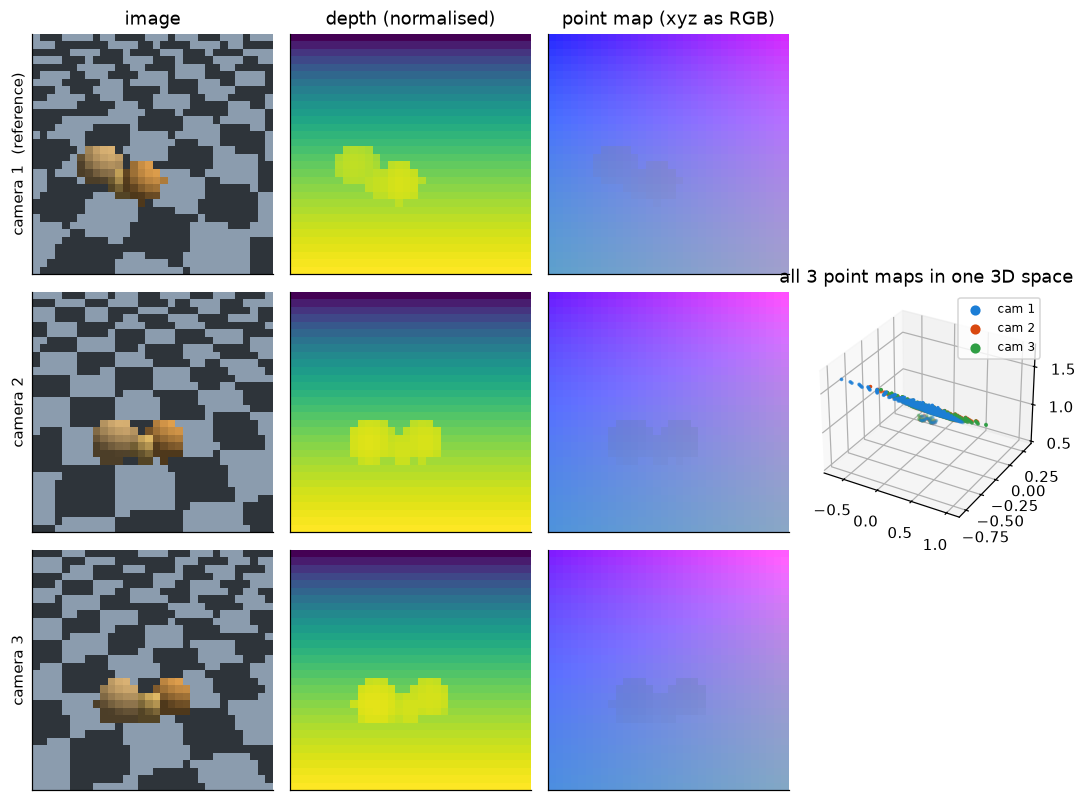

PASS  unproject(GT depth, GT camera) reproduces the GT point map  (depth + camera => points)   [max err 3.6e-07]
PASS  camera 1 is the reference: quaternion [0,0,0,1], translation 0
PASS  scale normalised: mean distance of all 3D points to the origin = 1
PASS  no pixel sees the sky (every pixel has a finite depth)


In [5]:
g = torch.Generator().manual_seed(3)
b = make_batch(6, gen=g)
print({k: tuple(v.shape) for k, v in b.items()})

fig, axs = plt.subplots(3, 4, figsize=(10, 7.4))
for r in range(3):
    for c in range(3): pass
for i in range(3):
    axs[i, 0].imshow(b["img"][0, i].permute(1, 2, 0)); axs[i, 0].set_ylabel(f"camera {i+1}" + ("  (reference)" if i == 0 else ""))
    axs[i, 1].imshow(b["depth"][0, i], cmap="viridis_r"); axs[i, 2].imshow((b["pmap"][0, i].permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))
    axs[i, 3].axis("off")
for ax, t in zip(axs[0], ["image", "depth (normalised)", "point map (xyz as RGB)", ""]): ax.set_title(t)
for ax in axs[:, :3].ravel(): ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax3 = fig.add_subplot(1, 4, 4, projection="3d"); ax3.set_title("all 3 point maps in one 3D space")
for i, col in enumerate(["#1c7ed6", "#d9480f", "#2f9e44"]):
    p = b["pmap"][0, i].reshape(3, -1)[:, ::3]; ax3.scatter(p[0], p[1], p[2], s=2, c=col, label=f"cam {i+1}")
ax3.legend(markerscale=4, fontsize=8); plt.tight_layout(); plt.show()

# --- the three facts we rely on
Hh, Ww = 32, 32
P_re = unproject(b["depth"], b["cam"], Hh, Ww)
check("unproject(GT depth, GT camera) reproduces the GT point map  (depth + camera => points)", (P_re - b["pmap"]).abs().max() < 1e-4, f"max err {(P_re - b['pmap']).abs().max():.1e}")
check("camera 1 is the reference: quaternion [0,0,0,1], translation 0", torch.allclose(b["cam"][:, 0, :7], torch.tensor([0, 0, 0, 1., 0, 0, 0]), atol=1e-5))
check("scale normalised: mean distance of all 3D points to the origin = 1", abs(b["pmap"].norm(dim=2).flatten(1).mean(1) - 1).max() < 1e-4)
check("no pixel sees the sky (every pixel has a finite depth)", bool((b["depth"] < 1e3).all()))

**What you see:** three photos of the same scene from different angles. Their **point maps** (third column; xyz coloured as RGB) are all in camera 1's coordinates - so in the 3D plot the three clouds **overlap** on the same floor and spheres. *That* is the "viewpoint-invariant point map" idea: every pixel of every image lands in one shared 3D space.

## Step 5 - Build: turn images into tokens (patchify)

A transformer eats a **sequence of vectors**, not a grid of pixels. So we cut each image into non-overlapping `p x p` patches (here `4x4`; real VGGT: `14x14`) and map each patch (`3*p*p` numbers) to a `C`-dimensional vector with **one shared linear layer**. A convolution with `kernel = stride = p` does exactly that in one line.

A 32x32 image with `p=4` -> an 8x8 grid -> **64 tokens per image**. (Real VGGT: 518x518 with `p=14` -> 37x37 = **1369 tokens per image**.)

In [6]:
class PatchEmbed(nn.Module):
    """Image -> tokens. A conv with kernel = stride = patch size  ==  'cut into patches, apply ONE shared linear layer'."""
    def __init__(self, patch, dim, in_ch=3):
        super().__init__(); self.patch = patch; self.proj = nn.Conv2d(in_ch, dim, patch, patch)
    def forward(self, img):                                    # (B*N, 3, H, W)
        return self.proj(img).flatten(2).transpose(1, 2)       # (B*N, T, C)   T = (H/p)*(W/p)

image (2, 3, 32, 32) -> (2, 64, 96)   (batch, tokens, channels)
PASS  conv patch-embedding == unfold patches + linear layer
PASS  32x32 image, patch 4 -> 64 tokens


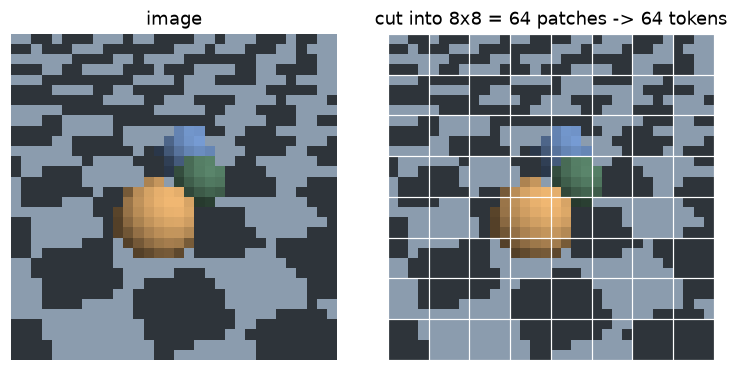

In [7]:
pe = PatchEmbed(4, 96); img = make_batch(2, gen=torch.Generator().manual_seed(1))["img"][:, 0]     # (2, 3, 32, 32)
tok = pe(img); print("image", tuple(img.shape), "->", tuple(tok.shape), "  (batch, tokens, channels)")

# Prove the conv really is "cut patches + one shared linear layer":
patches = F.unfold(img, kernel_size=4, stride=4).transpose(1, 2)                  # (2, 64, 3*4*4): every row is one flattened patch
manual = patches @ pe.proj.weight.flatten(1).T + pe.proj.bias                     # same weights as a plain matrix multiply
check("conv patch-embedding == unfold patches + linear layer", torch.allclose(tok, manual, atol=1e-5))
check("32x32 image, patch 4 -> 64 tokens", tok.shape[1] == 64)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.4))
axs[0].imshow(img[0].permute(1, 2, 0)); axs[0].set_title("image"); axs[1].imshow(img[0].permute(1, 2, 0)); axs[1].set_title("cut into 8x8 = 64 patches -> 64 tokens")
for k in range(9): axs[1].axhline(k * 4 - .5, color="w", lw=.8); axs[1].axvline(k * 4 - .5, color="w", lw=.8)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

## Step 6 - Build: camera token and register tokens (and why frame 1 is special)

After patchifying, each frame has `T` patch tokens. VGGT prepends **5 extra tokens** per frame:

* **1 camera token** - an empty learnable slot. It starts as a constant, and through attention it *gathers* what the network learns about *this* camera. At the end, only this token is read by the camera head. (Compare BERT's `[CLS]` token.)
* **4 register tokens** - extra scratch-pad slots that the transformer can use for internal bookkeeping (from the "Vision Transformers Need Registers" paper). They are discarded at the output.

**The clever bit:** frame 1 gets its **own separate learnable camera/register tokens**; frames 2...N all share another set. Because frame 1 *looks different to the network*, the network can learn *"the frame with these special tokens is the reference - express everything in its coordinates."* No special-case code: the reference frame is just a different token.

*A detail we simplify:* the paper does not say how positions inside an image are encoded; we add a plain learned positional embedding per patch (see `MiniVGGT` later). I believe the released code uses rotary position embeddings - check the repo if you need to match it exactly.

In [8]:
class SpecialTokens(nn.Module):
    """Prepend 1 camera token + R register tokens to every frame's patch tokens.
    The FIRST frame gets its own learnable set, all other frames share another set - that is how the
    network knows 'frame 0 is the reference coordinate system'."""
    def __init__(self, dim, n_reg=4):
        super().__init__(); self.n_special = 1 + n_reg
        self.first = nn.Parameter(torch.randn(1, 1, self.n_special, dim) * 0.02)
        self.other = nn.Parameter(torch.randn(1, 1, self.n_special, dim) * 0.02)
    def forward(self, tok):                                    # tok: (B, N, T, C)
        B, N, T, C = tok.shape
        special = torch.cat([self.first.expand(B, 1, -1, -1), self.other.expand(B, N - 1, -1, -1)], 1)   # (B,N,S,C)
        return torch.cat([special, tok], 2)                    # (B, N, S+T, C): [camera, reg x R, patches...]

In [9]:
st = SpecialTokens(96); x = torch.randn(2, 3, 64, 96)              # (batch, N=3 frames, 64 patch tokens, 96 dims)
y = st(x); print("before:", tuple(x.shape), " after adding 1 camera + 4 register tokens:", tuple(y.shape))
check("each frame gets 1 + 4 = 5 extra tokens in front", y.shape == (2, 3, 69, 96))
check("frame 1's special tokens differ from frame 2's (so frame 1 is identifiable)", not torch.allclose(st.first, st.other))
nn.init.normal_(st.first); nn.init.normal_(st.other)
y = st(x)
check("frames 2 and 3 share the same special tokens", torch.allclose(y[:, 1, :5], y[:, 2, :5]))
check("frame 1 uses a different set from frame 2", not torch.allclose(y[:, 0, :5], y[:, 1, :5]))
check("patch tokens are untouched (after the 5 special ones)", torch.equal(y[:, :, 5:], x))

before: (2, 3, 64, 96)  after adding 1 camera + 4 register tokens: (2, 3, 69, 96)
PASS  each frame gets 1 + 4 = 5 extra tokens in front
PASS  frame 1's special tokens differ from frame 2's (so frame 1 is identifiable)
PASS  frames 2 and 3 share the same special tokens
PASS  frame 1 uses a different set from frame 2
PASS  patch tokens are untouched (after the 5 special ones)


## Step 7 - Build: attention and the transformer block

**Attention in plain words.** Every token asks a *question* (**query**, `q`), advertises *what it contains* (**key**, `k`), and carries a *payload* (**value**, `v`). Token `i` compares its query to every token's key (a dot product = "how relevant are you to me?"), turns those scores into weights that sum to 1 (**softmax**), and takes a **weighted average of the values**. Result: each token's new vector is *a mixture of the other tokens' information*, weighted by relevance.

&nbsp;&nbsp;&nbsp;&nbsp;`Attention(Q, K, V) = softmax( Q K^T / sqrt(d) ) V`

*Multi-head* = do this several times in parallel with different learned projections, so different heads can look for different things (one head: "same colour", another: "same position in the floor pattern"). The `/ sqrt(d)` keeps the dot products from growing with `d` and saturating the softmax.

A **transformer block** = attention + a small MLP, each wrapped with LayerNorm and a **residual connection** (`x + ...`). Those `x +` are the exact skip connections from ResNet - they are why 48-block transformers train at all.

In [10]:
class Attention(nn.Module):
    """Multi-head self-attention written out by hand (set manual=False to use PyTorch's fused kernel)."""
    def __init__(self, dim, heads, manual=False):
        super().__init__(); self.h, self.manual = heads, manual
        self.qkv, self.proj = nn.Linear(dim, 3 * dim), nn.Linear(dim, dim)
    def forward(self, x):                                      # (B, L, C): every one of the L tokens looks at all L tokens
        B, L, C = x.shape
        q, k, v = self.qkv(x).view(B, L, 3, self.h, C // self.h).permute(2, 0, 3, 1, 4)   # each (B, heads, L, C/heads)
        if self.manual:
            att = (q @ k.transpose(-2, -1)) / math.sqrt(C // self.h)                       # (B, heads, L, L) similarity of every pair
            out = att.softmax(-1) @ v                                                       # weighted average of values
        else:
            out = F.scaled_dot_product_attention(q, k, v)
        return self.proj(out.transpose(1, 2).reshape(B, L, C))

class Block(nn.Module):
    """Standard pre-LayerNorm transformer block.  Notice the two `x + ...`: these are ResNet skip connections!"""
    def __init__(self, dim, heads, mlp_ratio=4):
        super().__init__()
        self.n1, self.attn = nn.LayerNorm(dim), Attention(dim, heads)
        self.n2, self.mlp = nn.LayerNorm(dim), nn.Sequential(nn.Linear(dim, mlp_ratio * dim), nn.GELU(), nn.Linear(mlp_ratio * dim, dim))
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

In [11]:
torch.manual_seed(0)
attn = Attention(96, 4); x = torch.randn(2, 70, 96)
attn.manual = True;  out_manual = attn(x)
attn.manual = False; out_fused = attn(x)
check("hand-written attention == PyTorch's fused scaled_dot_product_attention", torch.allclose(out_manual, out_fused, atol=1e-5))

# attention weights are a probability distribution over tokens: look at one head
with torch.no_grad():
    B, L, C = x.shape; q, k, v = attn.qkv(x).view(B, L, 3, 4, C // 4).permute(2, 0, 3, 1, 4)
    A = ((q @ k.transpose(-2, -1)) / math.sqrt(C // 4)).softmax(-1)
check("each token's attention weights sum to 1", torch.allclose(A.sum(-1), torch.ones(2, 4, 70), atol=1e-5))
blk = Block(96, 4); y = blk(x)
check("block output keeps the shape (batch, tokens, dim)", y.shape == x.shape)
nn.init.zeros_(blk.attn.proj.weight); nn.init.zeros_(blk.attn.proj.bias); nn.init.zeros_(blk.mlp[2].weight); nn.init.zeros_(blk.mlp[2].bias)
check("residual connections: zeroing the two output projections turns the block into the identity", torch.allclose(blk(x), x))

PASS  hand-written attention == PyTorch's fused scaled_dot_product_attention
PASS  each token's attention weights sum to 1
PASS  block output keeps the shape (batch, tokens, dim)
PASS  residual connections: zeroing the two output projections turns the block into the identity


## Step 8 - Build: Alternating Attention (VGGT's key idea)

Now we have `N` images, each with `L = 5 + T` tokens. We must let the images **share information** (that is how the network works out *where* each camera is relative to the others) - but full attention over all `N*L` tokens is expensive and, the authors argue, makes it harder to *normalise* each image's own features. Their compromise: **alternate**.

| layer type | which tokens does a token see? | tensor reshape | purpose |
|---|---|---|---|
| **frame-wise** self-attention | only tokens of **its own image** | `(B, N, L, C) -> (B*N, L, C)` | understand each image on its own (what is nearby, what is a surface) |
| **global** self-attention | tokens of **all images** | `(B, N, L, C) -> (B, N*L, C)` | match across images, compare viewpoints |

**The whole trick is a `reshape`:** the frame index `N` is either folded into the batch dimension (frames can't see each other) or folded into the sequence dimension (they can). The blocks themselves are identical. VGGT stacks `L=24` pairs `[frame -> global]`.

> Note: there is **no cross-attention** anywhere - only self-attention, just over different groupings of tokens. The paper tried cross-attention and found it worse (Table 5).

In [12]:
class AlternatingAttention(nn.Module):
    """VGGT's backbone: `depth` times  [ frame-wise block  ->  global block ].
    Same blocks, same parameters - only the RESHAPE differs:
       frame-wise : (B, N, L, C) -> (B*N, L, C)   each frame is its own sequence  (frames cannot see each other)
       global     : (B, N, L, C) -> (B, N*L, C)   all frames form ONE sequence    (every token sees every frame)"""
    def __init__(self, dim, heads, depth, mode="alternating"):
        super().__init__(); self.mode = mode
        n_frame = depth if mode == "alternating" else 0
        n_glob = depth if mode == "alternating" else 2 * depth          # 'global' ablation keeps the same total of 2L blocks
        self.frame_blocks = nn.ModuleList(Block(dim, heads) for _ in range(n_frame))
        self.global_blocks = nn.ModuleList(Block(dim, heads) for _ in range(n_glob))
    def forward(self, x):                                      # (B, N, L, C)
        B, N, L, C = x.shape
        if self.mode == "alternating":
            for fb, gb in zip(self.frame_blocks, self.global_blocks):
                x = fb(x.reshape(B * N, L, C)).reshape(B, N, L, C)
                x = gb(x.reshape(B, N * L, C)).reshape(B, N, L, C)
        else:
            for gb in self.global_blocks: x = gb(x.reshape(B, N * L, C)).reshape(B, N, L, C)
        return x

In [13]:
torch.manual_seed(0)
aa = AlternatingAttention(dim=96, heads=4, depth=2).eval()
B, N, L, C = 2, 3, 69, 96
x = torch.randn(B, N, L, C); x2 = x.clone(); x2[:, 1] += torch.randn(B, L, C)        # change ONLY frame 2

fb, gb = aa.frame_blocks[0].eval(), aa.global_blocks[0].eval()
with torch.no_grad():
    frame = lambda t: fb(t.reshape(B * N, L, C)).reshape(B, N, L, C)
    glob  = lambda t: gb(t.reshape(B, N * L, C)).reshape(B, N, L, C)
    d_frame = (frame(x) - frame(x2)).abs().amax(dim=(0, 2, 3))     # effect of editing frame 2, on each frame
    d_glob  = (glob(x)  - glob(x2)).abs().amax(dim=(0, 2, 3))
print("edit frame 2 ->  change in output of frames 1,2,3")
print("  frame-wise layer:", [f"{v:.1e}" for v in d_frame.tolist()], "   <- frames 1 and 3 untouched: frames are isolated")
print("  global layer    :", [f"{v:.1e}" for v in d_glob.tolist()],  "   <- every frame changes: information flows between frames")
check("frame-wise attention: editing frame 2 does NOT change frames 1 and 3", d_frame[0] == 0 and d_frame[2] == 0 and d_frame[1] > 0)
check("global attention: editing frame 2 DOES change frames 1 and 3", d_glob[0] > 1e-4 and d_glob[2] > 1e-4)
check("alternating attention keeps the tensor shape", aa(x).shape == x.shape)
n_alt = sum(p.numel() for p in AlternatingAttention(96, 4, 2, "alternating").parameters()); n_glob = sum(p.numel() for p in AlternatingAttention(96, 4, 2, "global").parameters())
check("'global-only' ablation variant has exactly the same number of parameters (fair comparison)", n_alt == n_glob, f"{n_alt:,} vs {n_glob:,}")

edit frame 2 ->  change in output of frames 1,2,3
  frame-wise layer: ['0.0e+00', '4.5e+00', '0.0e+00']    <- frames 1 and 3 untouched: frames are isolated
  global layer    : ['4.3e-02', '4.6e+00', '4.0e-02']    <- every frame changes: information flows between frames
PASS  frame-wise attention: editing frame 2 does NOT change frames 1 and 3
PASS  global attention: editing frame 2 DOES change frames 1 and 3
PASS  alternating attention keeps the tensor shape
PASS  'global-only' ablation variant has exactly the same number of parameters (fair comparison)   [447,360 vs 447,360]


### Why not just use global attention everywhere? Cost.

Attention compares every token with every other: cost grows with the **square** of the sequence length. With `N` frames of `T` tokens each:

* frame-wise layer: `N` separate sequences of length `T`  ->  cost ∝ `N · T²`
* global layer: one sequence of length `N·T`  ->  cost ∝ `(N·T)² = N² T²`

so global attention is **`N` times** more expensive than frame-wise. Alternating means half your layers are the cheap kind. With the *real* sizes (518 px, patch 14 -> `T = 1369 + 5 = 1374` tokens/frame, width 1024):

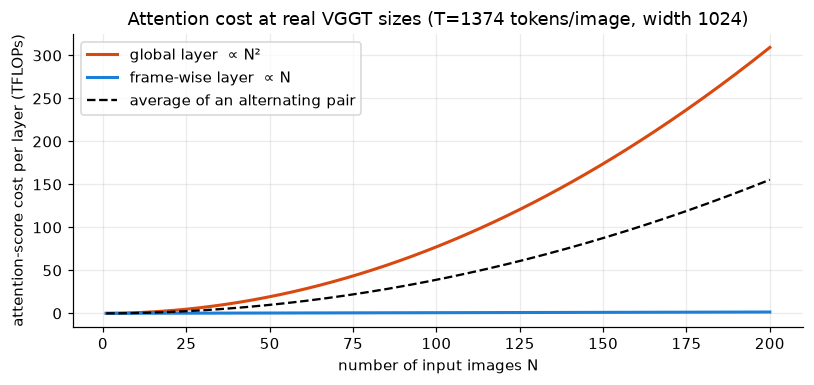

N=32 images: sequence length for a global layer = 43,968 tokens
PASS  global attention costs exactly N times a frame-wise layer


In [14]:
T_real, C_real = 37 * 37 + 5, 1024
Ns = np.arange(1, 201)
score_flops = lambda L_seq, n_seq: n_seq * 4 * L_seq ** 2 * C_real           # QK^T and (softmax)V: 2 matmuls x 2 FLOPs per MAC
frame_cost  = score_flops(T_real, Ns)                                        # N sequences of length T
global_cost = score_flops(Ns * T_real, 1)                                    # 1 sequence of length N*T
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(Ns, global_cost / 1e12, color=GLOBAL_C, lw=2, label="global layer  ∝ N²"); ax.plot(Ns, frame_cost / 1e12, color=FRAME_C, lw=2, label="frame-wise layer  ∝ N")
ax.plot(Ns, (global_cost + frame_cost) / 2e12, "--", color="k", lw=1.5, label="average of an alternating pair")
ax.set_xlabel("number of input images N"); ax.set_ylabel("attention-score cost per layer (TFLOPs)"); ax.set_title("Attention cost at real VGGT sizes (T=1374 tokens/image, width 1024)"); ax.legend(); plt.tight_layout(); plt.show()
print(f"N=32 images: sequence length for a global layer = {32 * T_real:,} tokens")
check("global attention costs exactly N times a frame-wise layer", np.allclose(global_cost / frame_cost, Ns))

## Step 9 - Build: the prediction heads

After the Alternating-Attention stack, each token has been enriched with information from its own image **and** all the other images. Now we **read the answers off**:

### Camera head
Take only the **camera token** of each frame (`B, N, C`). Run **4 more transformer blocks** over those `N` tokens (the cameras exchange information once more), then one **linear layer -> 9 numbers**: quaternion (4), translation (3), field of view (2). We normalise the quaternion to length 1 and make `w >= 0`; the field of view goes through `softplus` so it is positive.

### Dense head (depth, point map, track features, confidence)
Take the **patch tokens** and turn the sequence back into an image-shaped grid (`T = 64` -> 8x8), upsample by the patch size back to `32x32` and use convolutions to make per-pixel outputs. The paper uses the **DPT** head ("Vision Transformers for Dense Prediction"), which fuses features from several transformer depths and upsamples progressively; ours is a much smaller stand-in with the same *interface*:

| per-pixel output | activation | why |
|---|---|---|
| depth | `exp(·)` | depth must be positive |
| depth confidence `Σ_D` | `1 + exp(·)` | confidence >= 1 (the loss uses it as a weight; see Step 11) |
| point map (xyz) | none | any real coordinates |
| point confidence `Σ_P` | `1 + exp(·)` | same |
| track features `T` | none | descriptors for matching |

*Tracking:* the paper feeds the track features to a separate **CoTracker2** module. We implement a small stand-in in Step 11: correlate a query pixel's feature with every pixel of the other frames and take the soft-argmax.

In [15]:
class CameraHead(nn.Module):
    """camera token of every frame -> 4 extra attention blocks (the N cameras talk to each other) -> linear -> 9 numbers
    g = [quaternion (4), translation (3), field of view (2)]"""
    def __init__(self, dim, heads, n_blocks=4):
        super().__init__(); self.blocks = nn.Sequential(*[Block(dim, heads) for _ in range(n_blocks)])
        self.norm, self.out = nn.LayerNorm(dim), nn.Linear(dim, 9)
    def forward(self, cam_tok):                                # (B, N, C)
        g = self.out(self.norm(self.blocks(cam_tok)))
        q = F.normalize(g[..., :4], dim=-1); q = torch.where(q[..., 3:] < 0, -q, q)      # unit quaternion, w >= 0
        return torch.cat([q, g[..., 4:7], F.softplus(g[..., 7:9])], -1)                   # fov > 0

class DenseHead(nn.Module):
    """Patch tokens -> per-pixel outputs.  A simplified stand-in for the DPT head: tokens -> image-shaped feature map ->
    upsample x patch -> 3x3 convs.   Output channels: depth(1) + depth-uncertainty(1) + point map(3) + point-uncertainty(1) + track features(C_t)."""
    def __init__(self, dim, patch, hw, track_dim=8, hidden=64):
        super().__init__(); self.hw, self.track_dim = hw, track_dim
        self.up = nn.ConvTranspose2d(dim, hidden, patch, patch)
        self.net = nn.Sequential(nn.GELU(), nn.Conv2d(hidden, hidden, 3, padding=1), nn.GELU(), nn.Conv2d(hidden, 6 + track_dim, 3, padding=1))
    def forward(self, tok):                                    # (B*N, T, C)
        BN, T, C = tok.shape
        y = self.net(self.up(tok.transpose(1, 2).reshape(BN, C, *self.hw)))
        depth, d_conf = torch.exp(y[:, 0].clamp(-6, 4)), 1 + torch.exp(y[:, 1].clamp(max=4))   # depth > 0, confidence >= 1
        pmap, p_conf = y[:, 2:5], 1 + torch.exp(y[:, 5].clamp(max=4))
        return depth, d_conf, pmap, p_conf, y[:, 6:]

In [16]:
torch.manual_seed(0)
ch = CameraHead(96, 4); g_out = ch(torch.randn(2, 3, 96))
check("camera head: one 9-vector per frame", g_out.shape == (2, 3, 9))
check("predicted quaternions are unit length with w >= 0", torch.allclose(g_out[..., :4].norm(dim=-1), torch.ones(2, 3), atol=1e-5) and bool((g_out[..., 3] >= 0).all()))
check("predicted field of view is positive", bool((g_out[..., 7:] > 0).all()))
dh = DenseHead(96, patch=4, hw=(8, 8)); d, dc, pm, pc, tf = dh(torch.randn(6, 64, 96))      # (B*N=6 images, 64 tokens)
print("depth", tuple(d.shape), "| depth conf", tuple(dc.shape), "| point map", tuple(pm.shape), "| point conf", tuple(pc.shape), "| track feats", tuple(tf.shape))
check("dense head returns full-resolution (32x32) maps from 8x8 tokens", d.shape == (6, 32, 32) and pm.shape == (6, 3, 32, 32))
check("depth > 0 and confidence >= 1", bool((d > 0).all() and (dc >= 1).all() and (pc >= 1).all()))

PASS  camera head: one 9-vector per frame
PASS  predicted quaternions are unit length with w >= 0
PASS  predicted field of view is positive
depth (6, 32, 32) | depth conf (6, 32, 32) | point map (6, 3, 32, 32) | point conf (6, 32, 32) | track feats (6, 8, 32, 32)
PASS  dense head returns full-resolution (32x32) maps from 8x8 tokens
PASS  depth > 0 and confidence >= 1


## Step 10 - Put it together: `MiniVGGT`

Everything above wired into one module. Read `forward` top to bottom - it is the paper's Figure 2:

1. patchify every image -> tokens (+ position)
2. prepend camera + register tokens (frame 1 has its own set)
3. Alternating-Attention stack
4. camera token -> **camera head**; patch tokens -> **dense head**

In [17]:
class MiniVGGT(nn.Module):
    """A small but complete VGGT: DINO-style patchify -> +camera/register tokens -> Alternating-Attention x L -> camera head + dense head."""
    def __init__(self, img=32, patch=4, dim=96, heads=4, depth=4, n_reg=4, mode="alternating", track_dim=8):
        super().__init__(); self.hw = (img // patch, img // patch); T = self.hw[0] * self.hw[1]
        self.patch_embed = PatchEmbed(patch, dim)
        self.pos = nn.Parameter(torch.randn(1, T, dim) * 0.02)          # learned position of each patch inside its image
        self.special = SpecialTokens(dim, n_reg); self.S = self.special.n_special
        self.aa = AlternatingAttention(dim, heads, depth, mode)
        self.norm = nn.LayerNorm(dim)
        self.cam_head = CameraHead(dim, heads); self.dense_head = DenseHead(dim, patch, self.hw, track_dim)
    def forward(self, imgs):                                   # imgs (B, N, 3, H, W) in [0,1]
        B, N = imgs.shape[:2]; C = self.pos.shape[-1]
        tok = self.patch_embed(imgs.flatten(0, 1) - 0.5) + self.pos                # (B*N, T, C)
        x = self.aa(self.special(tok.view(B, N, -1, C)))                           # (B, N, S+T, C)
        x = self.norm(x)
        cams = self.cam_head(x[:, :, 0])                                           # camera token -> camera
        depth, d_conf, pmap, p_conf, feat = self.dense_head(x[:, :, self.S:].reshape(B * N, -1, C))   # patch tokens -> dense maps
        H, W = depth.shape[-2:]
        return dict(cam=cams, depth=depth.view(B, N, H, W), d_conf=d_conf.view(B, N, H, W),
                    pmap=pmap.view(B, N, 3, H, W), p_conf=p_conf.view(B, N, H, W), feat=feat.view(B, N, -1, H, W))

In [18]:
torch.manual_seed(0)
model = MiniVGGT(img=32, patch=4, dim=96, heads=4, depth=4)
batch = make_batch(2, gen=torch.Generator().manual_seed(0)); out = model(batch["img"])
print({k: tuple(v.shape) for k, v in out.items()})

parts = {"patch embed + pos": list(model.patch_embed.parameters()) + [model.pos], "special tokens": list(model.special.parameters()), "final LayerNorm": list(model.norm.parameters()),
         "alternating attention": list(model.aa.parameters()), "camera head": list(model.cam_head.parameters()), "dense head (DPT stand-in)": list(model.dense_head.parameters())}
tot = sum(p.numel() for p in model.parameters())
for k, v in parts.items(): print(f"  {k:28s} {sum(p.numel() for p in v):>9,}  ({100 * sum(p.numel() for p in v) / tot:4.1f}%)")
print(f"  {'TOTAL':28s} {tot:>9,}")
check("parts add up to the whole model", sum(sum(p.numel() for p in v) for v in parts.values()) == tot)
check("outputs: camera (B,N,9), depth (B,N,H,W), point map (B,N,3,H,W)", out["cam"].shape == (2, 3, 9) and out["depth"].shape == (2, 3, 32, 32) and out["pmap"].shape == (2, 3, 3, 32, 32))

# The paper's claim: 'permutation equivariant for all but the first frame'.  Swap frames 2 and 3 -> outputs for them must swap.
model.eval()
with torch.no_grad():
    o1 = model(batch["img"]); o2 = model(batch["img"][:, [0, 2, 1]])
model.train()
check("swapping frames 2 and 3 just swaps their outputs (equivariant for all but the first frame)",
      torch.allclose(o1["depth"][:, [0, 2, 1]], o2["depth"], atol=1e-4) and torch.allclose(o1["cam"][:, [0, 2, 1]], o2["cam"], atol=1e-4))
with torch.no_grad(): model.eval(); o3 = model(batch["img"][:, [1, 0, 2]]); model.train()
check("...but swapping frame 1 with another changes the answer (frame 1 is the reference)", not torch.allclose(o1["depth"][:, [1, 0, 2]], o3["depth"], atol=1e-4))

{'cam': (2, 3, 9), 'depth': (2, 3, 32, 32), 'd_conf': (2, 3, 32, 32), 'pmap': (2, 3, 3, 32, 32), 'p_conf': (2, 3, 32, 32), 'feat': (2, 3, 8, 32, 32)}
  patch embed + pos               10,848  ( 0.7%)
  special tokens                     960  ( 0.1%)
  final LayerNorm                    192  ( 0.0%)
  alternating attention          894,720  (59.7%)
  camera head                    448,425  (29.9%)
  dense head (DPT stand-in)      143,374  ( 9.6%)
  TOTAL                        1,498,519
PASS  parts add up to the whole model
PASS  outputs: camera (B,N,9), depth (B,N,H,W), point map (B,N,3,H,W)
PASS  swapping frames 2 and 3 just swaps their outputs (equivariant for all but the first frame)
PASS  ...but swapping frame 1 with another changes the answer (frame 1 is the reference)


## Step 11 - The loss: how it learns

The paper's total loss (their eq. 2):

&nbsp;&nbsp;&nbsp;&nbsp;`L = L_camera + L_depth + L_pmap + λ · L_track`, with `λ = 0.05`

* **`L_camera`**: Huber loss between predicted and true `g = [q, t, fov]`. (Huber = L2 near zero, L1 for big errors: robust.)
* **`L_depth`, `L_pmap`**: the **aleatoric-uncertainty loss** inherited from DUSt3R, plus a **gradient term** (so edges/slopes are right, not only values):

&nbsp;&nbsp;&nbsp;&nbsp;`L = ‖Σ ⊙ (D̂ − D)‖ + ‖Σ ⊙ (∇D̂ − ∇D)‖ − α log Σ`

* **`L_track`**: L1 distance between predicted and true 2D track positions.

*Deviation in our toy:* our camera targets are tiny numbers (rotations of ~0.1), so we weight the camera term **10x** (`w_cam = 10`) instead of the paper's 1. We also use `smooth_l1_loss` (Huber-style but on an L1 scale) - PyTorch's `huber_loss` multiplies the L1 region by `delta`, which silently shrinks the gradients when `delta` is small.

### The uncertainty trick, in plain words
The network outputs a **confidence `Σ`** for each pixel next to its prediction. The loss multiplies the error by `Σ` - so a confident wrong answer is expensive. If that were all, the network would just set `Σ = 0` and pay nothing. The **`− α log Σ`** term stops that: it *rewards* being confident. The balance gives: **trust yourself exactly as much as you are accurate** - set `Σ ≈ α / error`. Hard pixels (sky, glass, edges) automatically get low confidence; those are the pixels you should drop when building a clean point cloud. Let's verify that claim numerically rather than trust it:

In [19]:
def spatial_grad(x):                                           # finite differences along W and H
    return x[..., :, 1:] - x[..., :, :-1], x[..., 1:, :] - x[..., :-1, :]

def uncertainty_loss(pred, gt, conf, alpha=0.2):
    """Aleatoric-uncertainty loss used by VGGT/DUSt3R for depth and point maps:
         || conf * (pred - gt) ||  +  || conf * (grad pred - grad gt) ||  -  alpha * log(conf)
    pred, gt: (B,N,C,H,W)   conf: (B,N,H,W) >= 1.  Big conf = 'I trust this pixel' = errors cost more, but log term pays a price."""
    c = conf[:, :, None]
    data = (c * (pred - gt).abs()).mean()
    (px, py), (gx, gy) = spatial_grad(pred), spatial_grad(gt)
    grad = (c[..., :, 1:] * (px - gx).abs()).mean() + (c[..., 1:, :] * (py - gy).abs()).mean()
    return data + grad - alpha * conf.log().mean()

def track_loss(feat, pmap_gt, cam_gt, n_query=16, temp=10.0, gen=None):
    """Tiny tracking head.  Pick query pixels in frame 0; find where they land in every frame by feature correlation
    (soft-argmax over the correlation map); supervise with the geometric ground truth (reproject the 3D point).
    A one-step stand-in for the CoTracker2 module used in the paper."""
    B, N, Ct, H, W = feat.shape
    dev = feat.device
    idx = torch.randint(0, H * W, (B, n_query), generator=gen).to(dev)
    q_xyz = pmap_gt[:, 0].flatten(2).gather(2, idx[:, None].expand(B, 3, n_query))                      # (B,3,Q) 3D points, cam-0 frame
    q_feat = feat[:, 0].flatten(2).gather(2, idx[:, None].expand(B, Ct, n_query))                       # (B,Ct,Q)
    R = quat_to_mat(cam_gt[..., :4]); t = cam_gt[..., 4:7]; th = torch.tan(cam_gt[..., 7] / 2)           # (B,N)
    X = R @ q_xyz[:, None] + t[..., None]                                                                # (B,N,3,Q) in camera i
    uv_gt = X[:, :, :2] / X[:, :, 2:].clamp(min=1e-3) / th[..., None, None]                              # normalised coords in [-1,1]
    ys, xs = torch.meshgrid((torch.arange(H) + .5) / H * 2 - 1, (torch.arange(W) + .5) / W * 2 - 1, indexing="ij")
    grid = torch.stack([xs.flatten(), ys.flatten()], 0).to(dev)                                                  # (2, HW)
    corr = torch.einsum("bcq,bncp->bnqp", q_feat, feat.flatten(3)) / math.sqrt(Ct)                      # (B,N,Q,HW)
    uv_pred = torch.einsum("bnqp,dp->bndq", (corr * temp).softmax(-1), grid)                             # (B,N,2,Q) soft-argmax
    valid = (uv_gt.abs() < 1).all(2, keepdim=True).float()
    return ((uv_pred - uv_gt).abs() * valid).sum() / (valid.sum() * 2 + 1e-6)

def vggt_loss(out, gt, lam_track=0.05, alpha=0.2, w_cam=10.0):
    """L = w_cam*L_camera + L_depth + L_pmap + lambda * L_track   (paper eq. 2 uses w_cam = 1, lambda = 0.05;
    our toy's camera targets are tiny numbers, so we up-weight the camera term 10x - a deliberate deviation)"""
    l_cam = F.smooth_l1_loss(out["cam"], gt["cam"], beta=0.01)   # Huber-style: L2 below beta, L1 above (L1 scale, unlike F.huber_loss)
    l_depth = uncertainty_loss(out["depth"][:, :, None], gt["depth"][:, :, None], out["d_conf"], alpha)
    l_pmap = uncertainty_loss(out["pmap"], gt["pmap"], out["p_conf"], alpha)
    l_track = track_loss(out["feat"], gt["pmap"], gt["cam"])
    total = w_cam * l_cam + l_depth + l_pmap + lam_track * l_track
    return total, dict(cam=l_cam.item(), depth=l_depth.item(), pmap=l_pmap.item(), track=l_track.item(), total=total.item())

In [20]:
# For ONE pixel with fixed error e, minimise  Sigma*e - alpha*log(Sigma) over Sigma by gradient descent.
alpha = 0.2
for e in [0.01, 0.05, 0.2, 1.0]:
    s = torch.tensor(1.0, requires_grad=True); opt = torch.optim.Adam([s], lr=0.05)
    for _ in range(3000):
        loss = s * e - alpha * torch.log(s); opt.zero_grad(); loss.backward(); opt.step()
    print(f"error {e:5.2f}  ->  learned confidence {s.item():8.3f}   (alpha/error = {alpha / e:8.3f})")
    check(f"learned confidence = alpha / error  (error {e})", abs(s.item() - alpha / e) / (alpha / e) < 0.02)

# The loss function itself, on a toy pair of maps
gt_d = torch.rand(1, 1, 1, 8, 8) + 0.5
pred_close, pred_far = gt_d + 0.01, gt_d + 0.3
conf = torch.full((1, 1, 8, 8), 2.0)
check("uncertainty loss is larger for a worse prediction", uncertainty_loss(pred_far, gt_d, conf) > uncertainty_loss(pred_close, gt_d, conf))
check("uncertainty loss is 0 data-error + (-alpha*log conf) for a perfect prediction", abs(uncertainty_loss(gt_d, gt_d, conf).item() - (-0.2 * math.log(2.0))) < 1e-6)

error  0.01  ->  learned confidence   19.968   (alpha/error =   20.000)
PASS  learned confidence = alpha / error  (error 0.01)
error  0.05  ->  learned confidence    4.000   (alpha/error =    4.000)
PASS  learned confidence = alpha / error  (error 0.05)


error  0.20  ->  learned confidence    1.000   (alpha/error =    1.000)
PASS  learned confidence = alpha / error  (error 0.2)
error  1.00  ->  learned confidence    0.200   (alpha/error =    0.200)
PASS  learned confidence = alpha / error  (error 1.0)
PASS  uncertainty loss is larger for a worse prediction
PASS  uncertainty loss is 0 data-error + (-alpha*log conf) for a perfect prediction


### Ground-truth normalisation (why the scale is not a free choice)
A set of photos does not tell you the **scale** of the world (a toy house photographed from 10 cm looks identical to a real house photographed from 50 m) nor which point is the origin. If the training labels had arbitrary scales the network could never know what to output. So the authors make one canonical choice and **train the network to output it**:

1. express everything in camera 1's coordinates (done in `make_batch`)
2. compute the **average distance of all 3D points to the origin** and divide camera translations, depths and point maps by it.

We did exactly this (look back at the check "mean distance = 1"). At test time VGGT therefore predicts a scene whose average point distance is ~1 - *up to this convention, the units are arbitrary* (metric scale is not recoverable from images alone).

Finally the **combined loss** used for training:

In [21]:
gt = make_batch(8, gen=torch.Generator().manual_seed(2)); model = MiniVGGT()
total, parts = vggt_loss(model(gt["img"]), gt); total.backward()
print({k: round(v, 4) for k, v in parts.items()})
check("total = 10*camera + depth + pmap + 0.05*track   (paper: weight 1 on camera; we use 10 for the toy)", abs(parts["total"] - (10 * parts["cam"] + parts["depth"] + parts["pmap"] + 0.05 * parts["track"])) < 1e-3)
check("gradients reach the very first layer (patch embedding) and the camera token", model.patch_embed.proj.weight.grad.abs().sum() > 0 and model.special.first.grad.abs().sum() > 0)
check("gradients reach BOTH heads", all(p.grad is not None for p in model.cam_head.parameters()) and all(p.grad is not None for p in model.dense_head.parameters()))

{'cam': 0.5955, 'depth': 0.5532, 'pmap': 0.901, 'track': 0.4779, 'total': 7.433}
PASS  total = 10*camera + depth + pmap + 0.05*track   (paper: weight 1 on camera; we use 10 for the toy)
PASS  gradients reach the very first layer (patch embedding) and the camera token
PASS  gradients reach BOTH heads


## Step 12 - Train it, then measure

Training recipe, scaled down from the paper (AdamW, warm-up + cosine learning-rate, gradient-norm clipping at 1.0 - all as in the paper; ours: a few minutes on CPU instead of 9 days on 64 A100s). Every step draws **fresh random scenes**, so there is no overfitting to a fixed dataset.

In [22]:
def train(model, steps=1500, bs=24, lr=1e-3, seed=0, log_every=250, verbose=True):
    g = torch.Generator().manual_seed(seed); model.to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01); warm = steps // 20
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * s / steps)))   # warm-up + cosine, as in the paper
    hist = []; t0 = time.time()
    for s in range(steps):
        gt = {k: v.to(DEVICE) for k, v in make_batch(bs, gen=g).items()}
        loss, parts = vggt_loss(model(gt["img"]), gt)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()   # grad-clip 1.0, as in the paper
        hist.append(parts)
        if verbose and (s + 1) % log_every == 0: print(f"step {s+1:5d}  total {np.mean([h['total'] for h in hist[-log_every:]]):.4f}  cam {np.mean([h['cam'] for h in hist[-log_every:]]):.4f}  depth {np.mean([h['depth'] for h in hist[-log_every:]]):.4f}  ({time.time()-t0:.0f}s)")
    model.cpu()                                                  # back to CPU for inspection
    return hist

step   200  total 1.3618  cam 0.0675  depth 0.3250  (49s)


step   400  total 0.8322  cam 0.0491  depth 0.1339  (100s)


step   600  total 0.5515  cam 0.0446  depth -0.0268  (151s)


step   800  total 0.4920  cam 0.0437  depth -0.0645  (201s)


step  1000  total 0.4441  cam 0.0424  depth -0.0930  (253s)


step  1200  total 0.4167  cam 0.0419  depth -0.1115  (304s)


trained in 304s


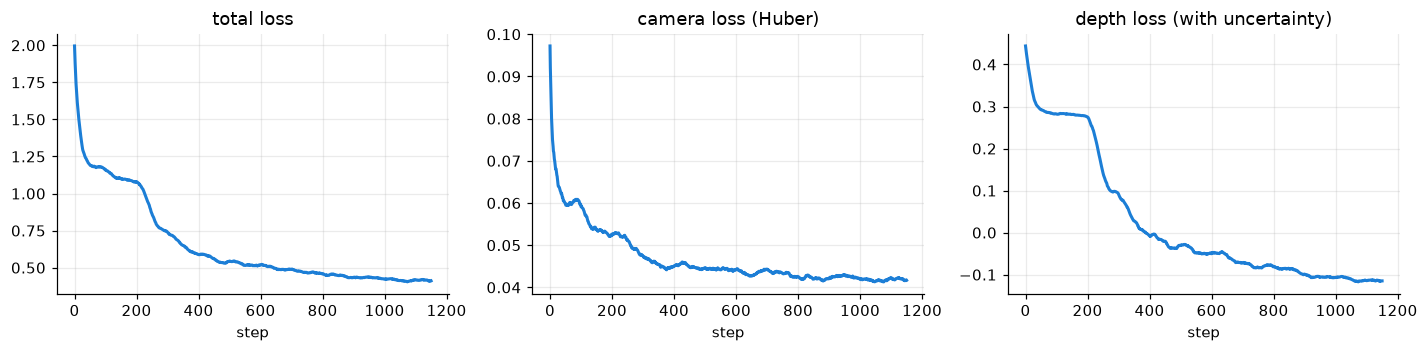

In [23]:
STEPS = 1200
torch.manual_seed(0)
vggt = MiniVGGT(img=32, patch=4, dim=96, heads=4, depth=4, mode="alternating")
t0 = time.time(); hist = train(vggt, steps=STEPS, bs=24, lr=1e-3, log_every=STEPS // 6); print(f"trained in {time.time() - t0:.0f}s")
sm = lambda k, w=50: np.convolve([h[k] for h in hist], np.ones(w) / w, "valid")
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, k, t in zip(axs, ["total", "cam", "depth"], ["total loss", "camera loss (Huber)", "depth loss (with uncertainty)"]): ax.plot(sm(k), lw=2, color=FRAME_C); ax.set_title(t); ax.set_xlabel("step")
plt.tight_layout(); plt.show()

### Evaluate on scenes the model has never seen
Each metric is printed **next to a naive baseline** so that "good" means something:

* *depth:* AbsRel = mean `|pred − true| / true`. Baseline: guess the same depth for every pixel.
* *rotation of cameras 2,3 relative to camera 1:* angle error in degrees. Baseline: "all cameras face the same way as camera 1" (identity).
* *translation:* distance error (in the normalised units). Baseline: "all cameras sit on camera 1" (zero).
* *field of view:* degrees. Baseline: always guess the mean.
* *point map:* mean absolute error per coordinate; compared both for the **point head** and for **depth + camera -> unproject** (the paper found the second more accurate).

In [24]:
@torch.no_grad()
def evaluate(model, n=256, seed=123):
    """Fresh scenes the model has never seen. Every metric is shown next to a naive baseline so 'good' means something."""
    model.eval().to(DEVICE); g = torch.Generator().manual_seed(seed); gt = make_batch(n, gen=g); out = {k: v.cpu() for k, v in model(gt["img"].to(DEVICE)).items()}; model.cpu().train()
    ang = lambda qa, qb: 2 * torch.acos((qa * qb).sum(-1).abs().clamp(max=1)) * 180 / math.pi          # angle between rotations, degrees
    ident = torch.tensor([0., 0, 0, 1]).expand_as(gt["cam"][..., :4])
    P_from_depth = unproject(out["depth"], out["cam"], *out["depth"].shape[-2:])                       # depth head + camera head -> points
    r = dict(
        depth_absrel=((out["depth"] - gt["depth"]).abs() / gt["depth"]).mean().item(),
        depth_absrel_base=((gt["depth"].median() - gt["depth"]).abs() / gt["depth"]).mean().item(),
        rot_err_deg=ang(out["cam"][:, 1:, :4], gt["cam"][:, 1:, :4]).mean().item(),
        rot_err_deg_base=ang(ident[:, 1:], gt["cam"][:, 1:, :4]).mean().item(),
        trans_err=(out["cam"][:, 1:, 4:7] - gt["cam"][:, 1:, 4:7]).norm(dim=-1).mean().item(),
        trans_err_base=gt["cam"][:, 1:, 4:7].norm(dim=-1).mean().item(),
        fov_err_deg=((out["cam"][..., 7] - gt["cam"][..., 7]).abs() * 180 / math.pi).mean().item(),
        fov_err_deg_base=((gt["cam"][..., 7] - gt["cam"][..., 7].mean()).abs() * 180 / math.pi).mean().item(),
        pmap_l1_head=(out["pmap"] - gt["pmap"]).abs().mean().item(),
        pmap_l1_depth_cam=(P_from_depth - gt["pmap"]).abs().mean().item(),
        pmap_l1_base=gt["pmap"].abs().mean().item(),
        cam0_quat_err=(out["cam"][:, 0, :4] - torch.tensor([0., 0, 0, 1])).abs().max().item())
    return r, gt, out

In [25]:
res, gt_e, out_e = evaluate(vggt)
rows = [("depth AbsRel",        res["depth_absrel"],   res["depth_absrel_base"]),
        ("rotation error (deg)", res["rot_err_deg"],    res["rot_err_deg_base"]),
        ("translation error",   res["trans_err"],      res["trans_err_base"]),
        ("field-of-view err (deg)", res["fov_err_deg"], res["fov_err_deg_base"]),
        ("point-map L1 (point head)", res["pmap_l1_head"],  res["pmap_l1_base"]),
        ("point-map L1 (depth+camera)", res["pmap_l1_depth_cam"], res["pmap_l1_base"])]
print(f"{'metric':30s}{'MiniVGGT':>10s}{'naive baseline':>16s}{'improvement':>14s}")
for n, v, bse in rows: print(f"{n:30s}{v:10.3f}{bse:16.3f}{bse / max(v, 1e-9):13.1f}x")
print(f"\ncamera-1 quaternion max deviation from identity [0,0,0,1]: {res['cam0_quat_err']:.3f}  (the network LEARNED to say 'I am the reference')")
check("depth beats the constant-depth baseline", res["depth_absrel"] < res["depth_absrel_base"])
check("field of view beats the 'always guess the mean' baseline", res["fov_err_deg"] < res["fov_err_deg_base"])
check("point-map head beats the zero-prediction baseline", res["pmap_l1_head"] < res["pmap_l1_base"])
check("camera 1 learned to output the identity pose (the reference frame)", res["cam0_quat_err"] < 0.05)
# HONEST REPORT (not asserted): did relative camera pose of frames 2,3 emerge in this tiny training budget?
pose_learned = res["rot_err_deg"] < 0.8 * res["rot_err_deg_base"]
print(f"\nrelative camera rotation: {res['rot_err_deg']:.2f} deg vs baseline {res['rot_err_deg_base']:.2f} deg  ->  " + ("LEARNED (>20% better than baseline)" if pose_learned else "NOT learned in this budget (still at the 'identity' baseline) - see the note below"))
check("depth + (unlearned or learned) camera -> unprojected points are still better than predicting zeros", res["pmap_l1_depth_cam"] < res["pmap_l1_base"])

metric                          MiniVGGT  naive baseline   improvement
depth AbsRel                       0.038           0.272          7.1x
rotation error (deg)              20.088          20.087          1.0x
translation error                  0.196           0.197          1.0x
field-of-view err (deg)            2.211           3.764          1.7x
point-map L1 (point head)          0.102           0.465          4.6x
point-map L1 (depth+camera)        0.065           0.465          7.2x

camera-1 quaternion max deviation from identity [0,0,0,1]: 0.002  (the network LEARNED to say 'I am the reference')
PASS  depth beats the constant-depth baseline
PASS  field of view beats the 'always guess the mean' baseline
PASS  point-map head beats the zero-prediction baseline
PASS  camera 1 learned to output the identity pose (the reference frame)

relative camera rotation: 20.09 deg vs baseline 20.09 deg  ->  NOT learned in this budget (still at the 'identity' baseline) - see the note below
P

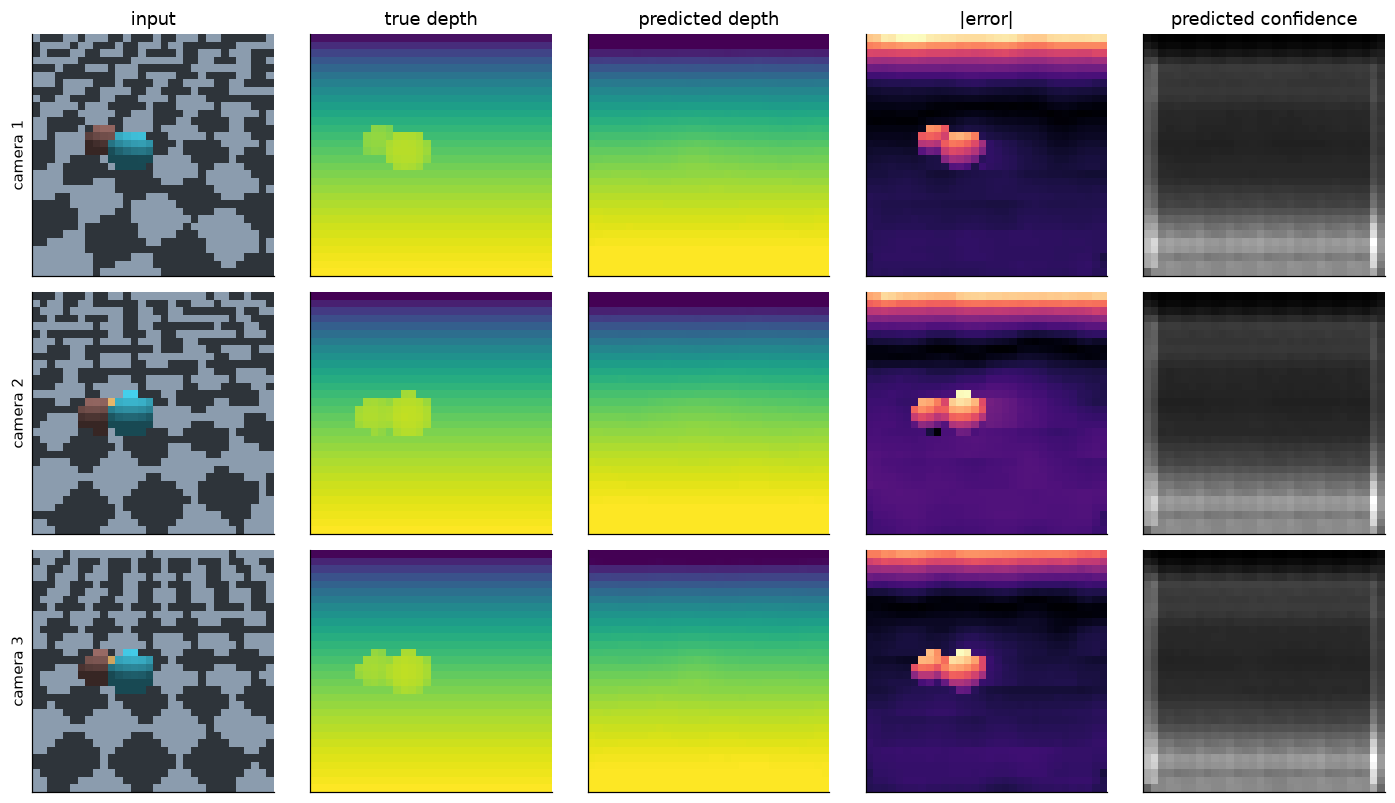

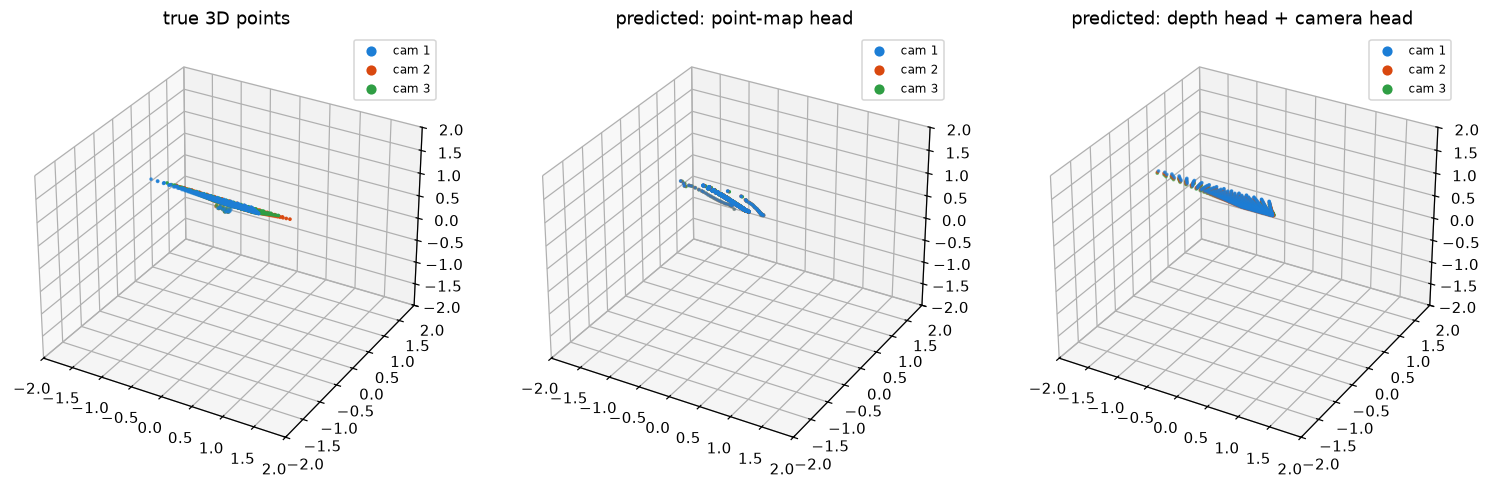

In [26]:
# See it: input images, true vs predicted depth, learned confidence, and 3D point clouds (true vs predicted, all in camera-1 space)
i = 0; fig, axs = plt.subplots(3, 5, figsize=(13, 7.4))
conf = out_e["d_conf"].detach()
for f in range(3):
    axs[f, 0].imshow(gt_e["img"][i, f].permute(1, 2, 0)); axs[f, 0].set_ylabel(f"camera {f+1}")
    vmin, vmax = gt_e["depth"][i].min(), gt_e["depth"][i].max()
    axs[f, 1].imshow(gt_e["depth"][i, f], cmap="viridis_r", vmin=vmin, vmax=vmax); axs[f, 2].imshow(out_e["depth"][i, f].detach(), cmap="viridis_r", vmin=vmin, vmax=vmax)
    axs[f, 3].imshow((out_e["depth"][i, f].detach() - gt_e["depth"][i, f]).abs(), cmap="magma"); axs[f, 4].imshow(conf[i, f], cmap="gray")
for ax, t in zip(axs[0], ["input", "true depth", "predicted depth", "|error|", "predicted confidence"]): ax.set_title(t)
for ax in axs.ravel(): ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

P_pred = unproject(out_e["depth"].detach(), out_e["cam"].detach(), 32, 32)
fig = plt.figure(figsize=(14, 4.4))
for k, (P, tt) in enumerate([(gt_e["pmap"], "true 3D points"), (out_e["pmap"], "predicted: point-map head"), (P_pred, "predicted: depth head + camera head")]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d"); ax.set_title(tt)
    for f, col in enumerate(["#1c7ed6", "#d9480f", "#2f9e44"]):
        p = P[i, f].reshape(3, -1)[:, ::2].detach(); ax.scatter(p[0], p[1], p[2], s=2, c=col, label=f"cam {f+1}")
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_zlim(-2, 2); ax.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()

**Reading the pictures:** the predicted depth recovers the floor's gradient and the sphere shapes. Compare the **error map** with the **confidence map** (right column): the model reports its *own* uncertainty without anyone labelling it - that is the `Σ` of the uncertainty loss at work.

**In the 3D plots** (true | point-map head | depth + camera head): the point-map head places the three views into a shared space reasonably well. The **depth + camera** panel is the one to read critically - it is only as good as the *camera head*, and see the next note.

> **An honest finding about our toy.** Depth, field of view, point maps and tracking learn quickly. **Relative camera rotation/translation of frames 2 and 3 did not emerge** in our few-minute budget (check the line printed above the plots; we also confirmed it with a camera-loss-only run of 800 steps). Estimating *how two cameras relate* requires matching features **across** images - the hardest thing the network learns, and the slowest to appear - and our model is ~1 M parameters trained for minutes on 32x32 images. The real VGGT is 1.2 B parameters trained 9 days on millions of real images (Step 14). Notice also what that implies for the paper's design: because the point head and the depth head are trained *per pixel with geometry-rich supervision*, they can learn well before pose does - exactly why the authors keep **all** the outputs as joint training signals. *Related caution:* in the table above "point-map L1 (depth+camera)" is lower than the point head's. In the paper that gap is a real finding, but with our pose unlearned it is **not** a clean replication - treat it as unverified here. (To make our toy's pose learn you would train far longer or on bigger/easier data; we leave that as an exercise rather than tune until the number looks good.)

**Tracking.** The same dense head also produced track features, trained with the geometric loss from Step 11. Does feature matching find the right pixel?

In [27]:
@torch.no_grad()
def track_error(model, n=128, seed=7, random_feats=False):
    g = torch.Generator().manual_seed(seed); gt = make_batch(n, gen=g); feat = model(gt["img"])["feat"]
    if random_feats: feat = torch.randn_like(feat)
    return track_loss(feat, gt["pmap"], gt["cam"], n_query=64, gen=torch.Generator().manual_seed(1)).item()
e_model, e_rand = track_error(vggt), track_error(vggt, random_feats=True)
print(f"mean 2D track error (normalised image coords, image width = 2):  trained {e_model:.3f}   random features {e_rand:.3f}")
check("trained track features localise matches better than random features", e_model < e_rand)

mean 2D track error (normalised image coords, image width = 2):  trained 0.235   random features 0.534
PASS  trained track features localise matches better than random features


## Step 13 - Does Alternating Attention really help? (a mini version of the paper's ablation)

The paper compares three backbones with the same parameter count on ETH3D point-map error (**lower is better**):

| backbone | Acc ↓ | Comp ↓ | Overall ↓ |
|---|---|---|---|
| cross-attention | 1.287 | 0.835 | 1.061 |
| global self-attention only | 1.032 | 0.621 | 0.827 |
| **alternating attention (VGGT)** | **0.901** | **0.518** | **0.709** |

*(paper Table 5)*. We repeat the idea at toy scale: same parameters, same data, same steps, same seed - only the attention pattern differs (`mode="global"` = 8 global blocks vs `mode="alternating"` = 4 frame + 4 global).

parameters  alternating: 1,498,519   global-only: 1,498,519


step   200  total 1.3793  cam 0.0691  depth 0.3255  (61s)


step   400  total 0.8493  cam 0.0487  depth 0.1481  (123s)


step   600  total 0.5411  cam 0.0447  depth -0.0336  (188s)


step   800  total 0.4717  cam 0.0435  depth -0.0806  (258s)


step  1000  total 0.4076  cam 0.0422  depth -0.1249  (336s)


step  1200  total 0.3754  cam 0.0417  depth -0.1491  (406s)


trained in 407s



metric                        alternating  global only
depth AbsRel                        0.038        0.032
rotation err (deg)                 20.088       20.088
translation err                     0.196        0.196
point-map L1 (depth+cam)            0.065        0.063

final training loss (last 100 steps)  alternating 0.4147   global-only 0.3739


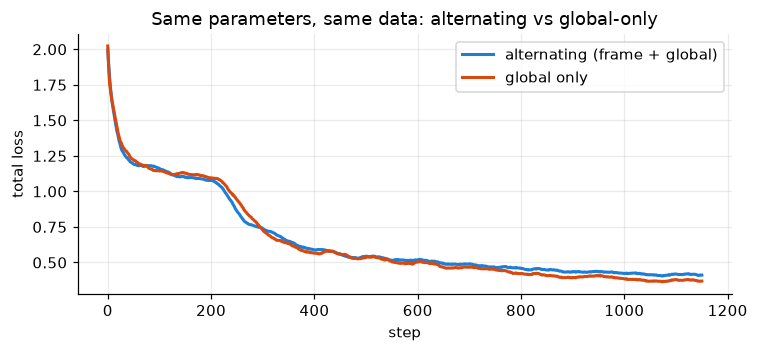

In [28]:
torch.manual_seed(0)
glob_only = MiniVGGT(img=32, patch=4, dim=96, heads=4, depth=4, mode="global")
print("parameters  alternating:", f"{sum(p.numel() for p in vggt.parameters()):,}", "  global-only:", f"{sum(p.numel() for p in glob_only.parameters()):,}")
t0 = time.time(); hist_g = train(glob_only, steps=STEPS, bs=24, lr=1e-3, log_every=STEPS // 6); print(f"trained in {time.time() - t0:.0f}s")
res_g, _, _ = evaluate(glob_only)
print(f"\n{'metric':28s}{'alternating':>13s}{'global only':>13s}")
for k, n in [("depth_absrel", "depth AbsRel"), ("rot_err_deg", "rotation err (deg)"), ("trans_err", "translation err"), ("pmap_l1_depth_cam", "point-map L1 (depth+cam)")]:
    print(f"{n:28s}{res[k]:13.3f}{res_g[k]:13.3f}")
final = lambda h: np.mean([x["total"] for x in h[-100:]])
print(f"\nfinal training loss (last 100 steps)  alternating {final(hist):.4f}   global-only {final(hist_g):.4f}")
fig, ax = plt.subplots(figsize=(7, 3.3)); w = 50
for h, lab, c in [(hist, "alternating (frame + global)", FRAME_C), (hist_g, "global only", GLOBAL_C)]: ax.plot(np.convolve([x["total"] for x in h], np.ones(w) / w, "valid"), lw=2, color=c, label=lab)
ax.set_xlabel("step"); ax.set_ylabel("total loss"); ax.set_title("Same parameters, same data: alternating vs global-only"); ax.legend(); plt.tight_layout(); plt.show()

In [29]:
better = lambda a, b: "alternating" if a < b else "global-only"
print("Verdict from THIS single-seed toy run (lower is better):")
print("  final training loss :", better(final(hist), final(hist_g)), f"wins  ({final(hist):.4f} vs {final(hist_g):.4f})")
print("  depth AbsRel        :", better(res["depth_absrel"], res_g["depth_absrel"]), f"wins  ({res['depth_absrel']:.3f} vs {res_g['depth_absrel']:.3f})")
print("  point-map L1 (head) :", better(res["pmap_l1_head"], res_g["pmap_l1_head"]), f"wins  ({res['pmap_l1_head']:.3f} vs {res_g['pmap_l1_head']:.3f})")
print("\nCaveat: one seed, one tiny model, ~1200 steps. Treat as a demonstration of HOW to run the ablation, not as evidence for or against the paper's table; the differences can easily flip with another seed.")
check("both variants trained to a finite loss", np.isfinite(final(hist)) and np.isfinite(final(hist_g)))

Verdict from THIS single-seed toy run (lower is better):
  final training loss : global-only wins  (0.4147 vs 0.3739)
  depth AbsRel        : global-only wins  (0.038 vs 0.032)
  point-map L1 (head) : global-only wins  (0.102 vs 0.101)

Caveat: one seed, one tiny model, ~1200 steps. Treat as a demonstration of HOW to run the ablation, not as evidence for or against the paper's table; the differences can easily flip with another seed.
PASS  both variants trained to a finite loss


## Step 14 - The real VGGT, and how to run it

| | our `MiniVGGT` | real VGGT (paper) |
|---|---|---|
| image size | 32 x 32 | up to 518 px on the long side |
| patch size / tokens per image | 4 / 64 | 14 / 37x37 = 1369 |
| backbone | plain patch embed | **DINO** ViT patchifier |
| Alternating-Attention depth `L` | 4 | **24** (24 frame + 24 global blocks) |
| camera head | 4 blocks + linear | 4 self-attention layers + linear (same) |
| dense head | tiny conv decoder | **DPT** |
| tracking | feature correlation soft-argmax | **CoTracker2** module |
| frames per scene | 3 | 2-24 in training; tested on up to hundreds |
| parameters | ~1 M | **~1.2 billion** |
| training | minutes, CPU | 160K iterations, 64 A100 GPUs, **9 days**, bf16 + gradient checkpointing |
| data | procedural spheres + floor | ~17 datasets (CO3D, ScanNet, MegaDepth, Kubric, Habitat, ...) |

Training details from the paper that we copied: AdamW, peak LR 2e-4 with 8K warm-up iterations and cosine decay, gradient clipping 1.0, random 2-24 frames per batch, colour-jitter / blur / grayscale augmentations, loss weights `1 : 1 : 1 : 0.05`.

### Running the released model
*(Not executed here - needs a GPU and a ~GB weight download. The snippet follows the project README as I remember it; check the repository for the current API.)*

```python
import torch
from vggt.models.vggt import VGGT
from vggt.utils.load_fn import load_and_preprocess_images

device = "cuda"
model = VGGT.from_pretrained("facebook/VGGT-1B").to(device)
images = load_and_preprocess_images(["scene/1.jpg", "scene/2.jpg", "scene/3.jpg"]).to(device)

with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    predictions = model(images)   # camera poses, depth maps, point maps, confidences, track features - one forward pass
```

Code and weights: github.com/facebookresearch/vggt (the paper links it on its first page).

## Step 15 - What is it good for?

**(paper) Figure 4 - point maps predicted on real photos** (camera frustums show the estimated poses):

<img src="vggt_assets/paper_fig4_pointmaps.png" width="760"/>

| application | how VGGT is used | paper evidence |
|---|---|---|
| **Camera pose estimation** (structure-from-motion) | read the camera head | beats optimisation-based SfM in 0.2 s (table below) |
| **Multi-view depth / dense reconstruction** | depth head + camera head, unproject to a point cloud | DTU: accuracy 0.389 without knowing the cameras, close to methods that are *given* them |
| **Point cloud / scene capture** from casual photos | point-map head | ETH3D, 0.2 s vs 7-9 s for DUSt3R / MASt3R |
| **Point tracking / feature matching** | track features + tracker | best two-view matching AUC on ScanNet among compared baselines; also helps dynamic tracking when fine-tuned |
| **Initialisation for classical pipelines** | feed VGGT's cameras and points to bundle adjustment | **"Ours (with BA)"**: even higher accuracy, 1.8 s total |
| **Feed-forward novel view synthesis** | fine-tune: replace the output heads so the network **renders a new view** from unposed photos | competitive with methods that *need* camera poses (below) |
| **A 3D-aware backbone** for other models | reuse the pretrained features | paper: "VGGT features significantly enhance downstream tasks" |

### Novel view synthesis from *unposed* photos
They fine-tune VGGT so it takes 4 input photos and the *ray image* of a target viewpoint and directly outputs the target image - **no input camera poses**:

<img src="vggt_assets/paper_fig6_nvs.png" width="420"/>

*(paper Fig. 6)* top row: input views, middle: ground truth, bottom: VGGT's synthesised views.

### The headline numbers (copied from the paper's tables; ↑ higher is better)

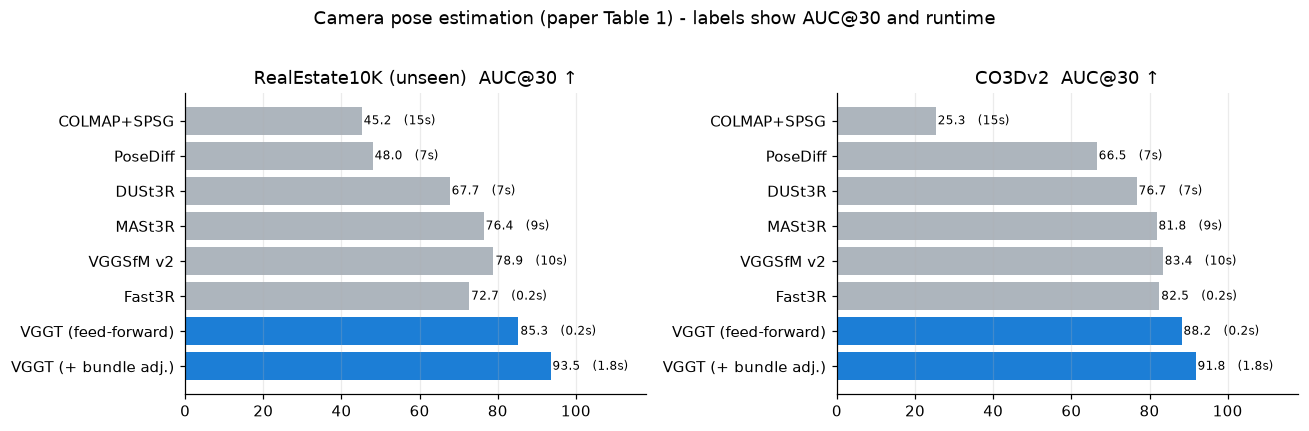

Ablations from the paper (ETH3D point-map 'Overall' error, lower = better):
  backbone:   cross-attention 1.061  |  global only 0.827  |  alternating 0.709
  multi-task: w/o camera loss 0.834  |  w/o depth loss 0.727  |  w/o track loss 0.790  |  all losses 0.709
PASS  paper numbers copied consistently: VGGT feed-forward beats MASt3R on both benchmarks


In [30]:
# Paper Table 1: camera pose AUC@30 (higher = better) and runtime on one H100. Copied from the paper.
tbl = [("COLMAP+SPSG", 45.2, 25.3, 15), ("PoseDiff", 48.0, 66.5, 7), ("DUSt3R", 67.7, 76.7, 7), ("MASt3R", 76.4, 81.8, 9),
       ("VGGSfM v2", 78.9, 83.4, 10), ("Fast3R", 72.7, 82.5, 0.2), ("VGGT (feed-forward)", 85.3, 88.2, 0.2), ("VGGT (+ bundle adj.)", 93.5, 91.8, 1.8)]
names = [r[0] for r in tbl]; fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
cols = [("#adb5bd" if "VGGT" not in n else "#1c7ed6") for n in names]
for ax, idx, t in [(axs[0], 1, "RealEstate10K (unseen)  AUC@30 ↑"), (axs[1], 2, "CO3Dv2  AUC@30 ↑")]:
    ax.barh(names, [r[idx] for r in tbl], color=cols); ax.invert_yaxis(); ax.set_title(t); ax.grid(axis="y", alpha=0)
    for y, r in enumerate(tbl): ax.text(r[idx] + .5, y, f"{r[idx]}   ({r[3]}s)", va="center", fontsize=8)
    ax.set_xlim(0, 118)
plt.suptitle("Camera pose estimation (paper Table 1) - labels show AUC@30 and runtime", y=1.02); plt.tight_layout(); plt.show()
print("Ablations from the paper (ETH3D point-map 'Overall' error, lower = better):")
print("  backbone:   cross-attention 1.061  |  global only 0.827  |  alternating 0.709")
print("  multi-task: w/o camera loss 0.834  |  w/o depth loss 0.727  |  w/o track loss 0.790  |  all losses 0.709")
check("paper numbers copied consistently: VGGT feed-forward beats MASt3R on both benchmarks", 85.3 > 76.4 and 88.2 > 81.8)

## Step 16 - Cheat sheet, misconceptions, further reading

### One-page summary
| piece | what it is | key shape (ours) |
|---|---|---|
| input | `N` photos of one scene | `(B, N, 3, 32, 32)` |
| patchify | conv `kernel=stride=patch` | -> `(B*N, 64, C)` |
| special tokens | 1 camera + 4 register per frame; **frame 1 has its own set** | -> `(B, N, 69, C)` |
| frame-wise attention | reshape `(B*N, L, C)` - frames isolated | cost ∝ `N·T²` |
| global attention | reshape `(B, N*L, C)` - frames mix | cost ∝ `N²·T²` |
| Alternating Attention | `[frame, global]` x `L` (real: 24) | same shape out |
| camera head | camera token -> 4 blocks -> linear | `(B, N, 9)` = quat 4 + trans 3 + fov 2 |
| dense head (DPT) | patch tokens -> depth, point map, confidence, track features | `(B, N, ·, H, W)` |
| unproject | `R^T (depth · ray − t)` | depth + camera ⇒ 3D points |
| loss | camera Huber + uncertainty-weighted depth & point map + 0.05 · track | |
| normalisation | frame 1 = origin; divide by mean point distance | scale is a *convention* |

### Common misconceptions
1. *"VGGT has built-in geometry (epipolar constraints, triangulation, BA)."* No. It is a **plain transformer**; the only 3D-aware design choices are the alternating attention pattern, the first-frame tokens and the output parametrisation. The geometry is *learned from data*.
2. *"The point map head and depth+camera give different things."* They are **redundant by design**; the paper found unprojecting the depth and camera heads is slightly **more accurate** than the point head (0.677 vs 0.709 overall on ETH3D) - decomposing a hard task into easier ones helps.
3. *"Frame order does not matter at all."* Order matters for **frame 1 only** (it defines the world frame). The rest is permutation-equivariant - we tested it.
4. *"It outputs metric (metres) depth."* No: depth is in the **normalised unit** where the average point distance is 1. Scale is a convention fixed at training time.
5. *"Global attention would be strictly better; alternating is a speed hack."* The paper's ablation (Step 13) shows alternating is **more accurate** at equal parameter count, not just cheaper - their explanation: frame-wise layers keep each image's activations well-normalised. Our toy run (printed in Step 13) is a single-seed demonstration, not proof.
6. *"It replaces all of SfM."* It beats classical pipelines in speed and often accuracy, and adding bundle adjustment on top still **improves** it - the two are complementary.

### Where this connects to what you already know
* Every `Block` is a **residual** block (`x + f(x)`) - see `01_resnet_residual_learning.ipynb`.
* The "special tokens" are the same trick as `[CLS]` in BERT/ViT and "registers" in DINOv2.
* "Predict several related outputs jointly" is multi-task learning - Table 6 shows it helps even when outputs are mathematically redundant.

### Further reading
* Wang, Chen, Karaev, Vedaldi, Rupprecht, Novotny. *VGGT: Visual Geometry Grounded Transformer.* CVPR 2025 - arXiv:2503.11651
* Wang et al. *DUSt3R: Geometric 3D Vision Made Easy.* CVPR 2024 - the two-view point-map predecessor (arXiv:2312.14132)
* Leroy et al. *MASt3R* (2024); Karaev et al. *CoTracker* (2023/24); Ranftl et al. *Vision Transformers for Dense Prediction (DPT)* (2021); Darcet et al. *Vision Transformers Need Registers* (2023)
* Hartley & Zisserman, *Multiple View Geometry in Computer Vision* - the classical theory (pinhole camera, epipolar geometry) that VGGT learns implicitly
* Schönberger & Frahm, *COLMAP* - the classical SfM pipeline VGGT is compared to

In [31]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

49/49 checks passed
